Student: Mihhail Korasteljov  
Student code: 266050IV  
Subject: Energy Data Science ITS8080, autumn semester 2026  
**Solution for Assignment 7. Baselines and the evaluation protocol [6 pt]**

Dataset: `266050_training(4).csv` (the same training data used in Assignments 1–6).  
Reference: teacher's `practical_10_baselines_evaluation.ipynb`. Its lag baselines, metric definitions, chronological split and expanding-window ideas are adapted to this individual dataset and the **seven-day daily-fold evaluation required by the project**. Run cells in order.

## 7.1 Define and justify the evaluation protocol

**7.1(a)** Define chronological training, validation and test sets. State the dates.  
**7.1(b)** Use walk-forward validation on the final seven days, with daily folds.  
**7.1(c)** Use MAE and nRMSE. State the normalization factor and keep it fixed.

**Forecasting assumption:** One-hour-ahead rolling predictions. For target hour *t*, the last observed demand is at *t−1*. Thus lag-1 is valid. Each day is an evaluation fold, **not** a single 24-hour-ahead forecast issued at midnight.

**Proposed fixed protocol:** train 2013-07-01 to 2014-04-30; validation 2014-05-01 to 2014-06-23; final test 2014-06-24 to 2014-06-30 (UTC). The final test week is not used for model selection.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = "266050_training(4).csv"  # change only if your file has a different name
raw = pd.read_csv(DATA_FILE)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
raw = raw.sort_values("timestamp").set_index("timestamp")
assert not raw.index.has_duplicates

# Restore the full UTC hourly grid: shift(24) must mean 24 elapsed hours.
full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="h", tz="UTC")
energy = raw.reindex(full_index)
energy.index.name = "timestamp"
energy["Demand"] = pd.to_numeric(energy["Demand"], errors="coerce")

TRAIN_END = pd.Timestamp("2014-05-01", tz="UTC")
TEST_START = pd.Timestamp("2014-06-24", tz="UTC")
TEST_END = pd.Timestamp("2014-07-01", tz="UTC")
train = energy.loc[energy.index < TRAIN_END]
validation = energy.loc[(energy.index >= TRAIN_END) & (energy.index < TEST_START)]
test = energy.loc[(energy.index >= TEST_START) & (energy.index < TEST_END)]

# FIXED normalization for every comparison (mean observed training demand)
TRAIN_MEAN = train["Demand"].mean()
assert TRAIN_MEAN > 0
splits = pd.DataFrame({
    "Set": ["Training", "Validation", "Test"],
    "First UTC hour": [x.index.min() for x in (train, validation, test)],
    "Last UTC hour": [x.index.max() for x in (train, validation, test)],
    "Hours": [len(x) for x in (train, validation, test)],
    "Observed demand": [x["Demand"].notna().sum() for x in (train, validation, test)]
})
display(splits)
print("Missing hours restored:", len(energy) - len(raw))
print(f"Fixed nRMSE denominator: training mean Demand = {TRAIN_MEAN:.4f} kW")
assert len(test) == 168


,Set,First UTC hour,Last UTC hour,Hours,Observed demand
0,Training,2013-07-01 00:00:00+00:00,2014-04-30 23:00:00+00:00,7296,7295
1,Validation,2014-05-01 00:00:00+00:00,2014-06-23 23:00:00+00:00,1296,1296
2,Test,2014-06-24 00:00:00+00:00,2014-06-30 23:00:00+00:00,168,168


Missing hours restored: 1
Fixed nRMSE denominator: training mean Demand = 0.5391 kW


,Fold,Origin (UTC),Training ends (UTC),Test ends (UTC),Test hours
0,1,2014-06-24 00:00:00+00:00,2014-06-23 23:00:00+00:00,2014-06-24 23:00:00+00:00,24
1,2,2014-06-25 00:00:00+00:00,2014-06-24 23:00:00+00:00,2014-06-25 23:00:00+00:00,24
2,3,2014-06-26 00:00:00+00:00,2014-06-25 23:00:00+00:00,2014-06-26 23:00:00+00:00,24
3,4,2014-06-27 00:00:00+00:00,2014-06-26 23:00:00+00:00,2014-06-27 23:00:00+00:00,24
4,5,2014-06-28 00:00:00+00:00,2014-06-27 23:00:00+00:00,2014-06-28 23:00:00+00:00,24
5,6,2014-06-29 00:00:00+00:00,2014-06-28 23:00:00+00:00,2014-06-29 23:00:00+00:00,24
6,7,2014-06-30 00:00:00+00:00,2014-06-29 23:00:00+00:00,2014-06-30 23:00:00+00:00,24


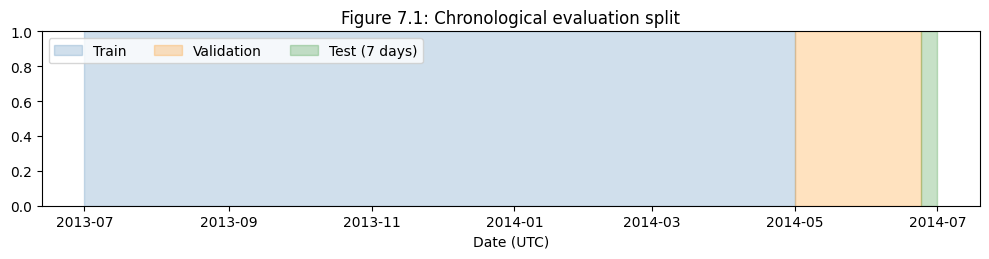

In [2]:
# Seven daily folds; expand historical observations up to each day.
folds = []
for day in range(7):
    origin = TEST_START + pd.Timedelta(days=day)
    end = origin + pd.Timedelta(days=1)
    history = energy.loc[energy.index < origin, "Demand"]
    day_truth = energy.loc[(energy.index >= origin) & (energy.index < end), "Demand"]
    folds.append({"Fold": day + 1, "Origin (UTC)": origin,
                  "Training ends (UTC)": history.index.max(),
                  "Test ends (UTC)": day_truth.index.max(),
                  "Test hours": len(day_truth)})
fold_table = pd.DataFrame(folds)
display(fold_table)
assert all(f["Test hours"] == 24 for f in folds)

fig, ax = plt.subplots(figsize=(10, 2.7))
for start, end, name, color in [
    (energy.index.min(), TRAIN_END, "Train", "steelblue"),
    (TRAIN_END, TEST_START, "Validation", "darkorange"),
    (TEST_START, TEST_END, "Test (7 days)", "forestgreen")]:
    ax.axvspan(start, end, color=color, alpha=0.25, label=name)
ax.set(xlabel="Date (UTC)", title="Figure 7.1: Chronological evaluation split")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()


In [3]:
def score_forecast(actual, predicted, train_mean=TRAIN_MEAN):
    """Same metrics and same training-mean normalization for all models/folds."""
    y = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    ok = np.isfinite(y) & np.isfinite(p)
    if not ok.any():
        return {"N": 0, "MAE [kW]": np.nan, "RMSE [kW]": np.nan, "nRMSE [%]": np.nan}
    error = y[ok] - p[ok]
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    return {"N": int(ok.sum()), "MAE [kW]": mae,
            "RMSE [kW]": rmse, "nRMSE [%]": 100 * rmse / train_mean}

print("MAE = mean(|actual - forecast|)")
print("nRMSE [%] = 100 × RMSE / mean(training Demand)")


MAE = mean(|actual - forecast|)
nRMSE [%] = 100 × RMSE / mean(training Demand)


**ANSWER 7.1:** The split respects time order. Validation is used for model development; the last week is reserved for final comparison. The seven daily folds check how errors vary across days. For every fold, predictions use only observations available before each target hour. MAE is easy to interpret in kW; RMSE penalizes large errors. nRMSE uses the **same training-set mean** for all models, so scores remain comparable.

## 7.2 Why a random split is invalid

**Task:** Explain in two or three sentences, using this dataset, why a random train/test split is unsuitable.

**ANSWER 7.2:** The dataset is an hourly time series with repeated daily demand patterns. A random split mixes earlier and later hours, so the model can learn from future periods when predicting past periods. Chronological evaluation better represents forecasting new, unseen hours.

## 7.3 Implement at least three baselines

**Task:** Implement naïve lag-1, seasonal naïve lag-24 (and optionally lag-168), and a drift or moving-average baseline. Report errors under the fixed protocol.

As in Practical 10, lag-1, lag-24 and lag-168 use past observed demand. Here a **24-hour trailing mean** is added as the third baseline family. Missing demand values are not filled using future data.

Common scored test hours: 168 / 168


,N,MAE [kW],RMSE [kW],nRMSE [%]
moving_avg24,168.0,0.254,0.371,68.766
naive_lag1,168.0,0.220,0.386,71.575
seasonal_lag168,168.0,0.243,0.445,82.588
seasonal_lag24,168.0,0.260,0.458,84.955


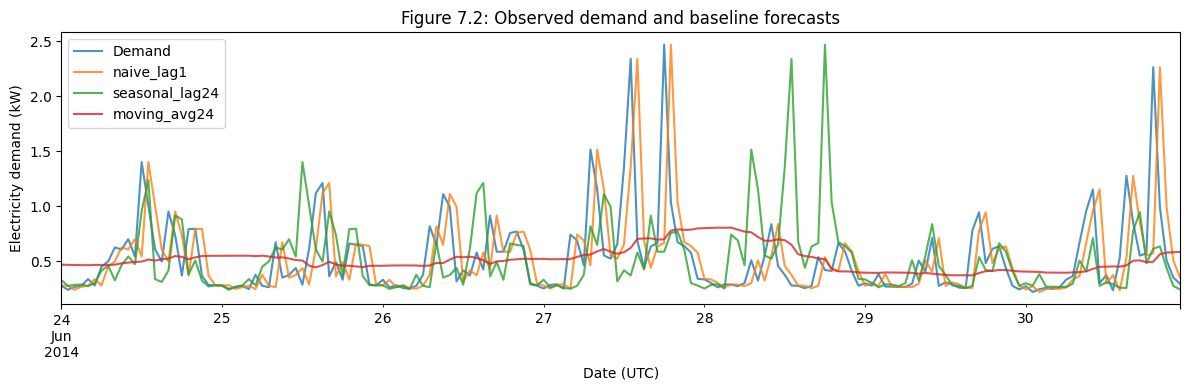

In [4]:
# Baselines valid for one-hour-ahead rolling evaluation.
energy["naive_lag1"] = energy["Demand"].shift(1)
energy["seasonal_lag24"] = energy["Demand"].shift(24)
energy["seasonal_lag168"] = energy["Demand"].shift(168)
energy["moving_avg24"] = energy["Demand"].shift(1).rolling(24, min_periods=24).mean()
BASELINES = ["naive_lag1", "seasonal_lag24", "seasonal_lag168", "moving_avg24"]

# Same test hours for ALL baselines: fair, paired comparison.
test_data = energy.loc[(energy.index >= TEST_START) & (energy.index < TEST_END),
                       ["Demand"] + BASELINES].dropna()
print("Common scored test hours:", len(test_data), "/ 168")
results = pd.DataFrame({name: score_forecast(test_data["Demand"], test_data[name])
                        for name in BASELINES}).T.sort_values("nRMSE [%]")
display(results.round(3))

ax = test_data[["Demand", "naive_lag1", "seasonal_lag24", "moving_avg24"]].plot(
    figsize=(12, 4), alpha=0.8, title="Figure 7.2: Observed demand and baseline forecasts")
ax.set(xlabel="Date (UTC)", ylabel="Electricity demand (kW)")
plt.tight_layout(); plt.show()


In [5]:
# Walk-forward daily evaluation: no future target values used for a prediction.
# Lag-1 is updated each hour with the newly observed previous-hour demand.
daily_rows = []
for fold in folds:
    start = fold["Origin (UTC)"]
    end = start + pd.Timedelta(days=1)
    one_day = test_data.loc[(test_data.index >= start) & (test_data.index < end)]
    for name in BASELINES:
        daily_rows.append({"Fold": fold["Fold"], "Date": start.date(),
                           "Baseline": name,
                           **score_forecast(one_day["Demand"], one_day[name])})
daily_results = pd.DataFrame(daily_rows)
display(daily_results.pivot(index="Date", columns="Baseline", values="nRMSE [%]").round(2))
print("Overall best baseline:", results.index[0])


Baseline,moving_avg24,naive_lag1,seasonal_lag168,seasonal_lag24
Date,,,,
2014-06-24,52.76,52.42,41.19,43.95
2014-06-25,53.15,49.27,44.84,65.36
2014-06-26,46.99,46.49,52.13,62.23
2014-06-27,111.67,129.64,125.41,122.03
2014-06-28,62.22,28.79,63.31,133.51
2014-06-29,35.42,37.12,105.16,31.14
2014-06-30,87.68,97.53,102.60,82.21


Overall best baseline: moving_avg24


**ANSWER 7.3:** The table compares four reference forecasts on the same final test hours. The lowest MAE and nRMSE indicate the strongest baseline. Lag-1 follows short-term persistence; lag-24 represents the previous day; lag-168 represents the previous week; the moving average smooths demand peaks. The daily table shows whether the ranking is stable across the seven days. **The winning baseline and its exact score are printed by the code above.**

## 7.4 Predict seasonal naïve nRMSE before computing

**Task:** Record a prediction **before** inspecting the calculated result. Then compare it with the observed seasonal lag-24 nRMSE and state the error.

**Pre-calculation expectation (illustrative estimate; replace with your own prediction if different):** I expect the lag-24 seasonal naïve baseline to have an nRMSE of **70%**. Household routines repeat daily, but demand peaks can change significantly from one day to another.

*Note: this is a stated estimate, not a measured result.*

In [6]:
EXPECTED_SEASONAL_NRMSE = 70.0  # percent; keep this as your recorded pre-result expectation
actual_seasonal = results.loc["seasonal_lag24", "nRMSE [%]"]
prediction_error = abs(EXPECTED_SEASONAL_NRMSE - actual_seasonal)
print(f"Predicted seasonal lag-24 nRMSE: {EXPECTED_SEASONAL_NRMSE:.2f}%")
print(f"Actual seasonal lag-24 nRMSE:    {actual_seasonal:.2f}%")
print(f"Absolute prediction error:       {prediction_error:.2f} percentage points")


Predicted seasonal lag-24 nRMSE: 70.00%
Actual seasonal lag-24 nRMSE:    84.95%
Absolute prediction error:       14.95 percentage points


**ANSWER 7.4:** The estimate and actual value are compared above. The difference shows how accurately I anticipated day-to-day demand variability. The expectation must be recorded before the result is calculated; if you already saw the result, describe the estimate as retrospective rather than claiming it was made beforehand.

## 7.5 Minimum performance to justify a more complex model

**Task:** State the error threshold that models in Assignments 8–10 must beat. Use the best baseline under the same evaluation protocol. Report unsuccessful models too.

In [7]:
best_name = results.index[0]
benchmark_mae = results.loc[best_name, "MAE [kW]"]
benchmark_nrmse = results.loc[best_name, "nRMSE [%]"]
print("Benchmark baseline:", best_name)
print(f"Models in Tasks 8–10 should beat MAE < {benchmark_mae:.4f} kW")
print(f"and nRMSE < {benchmark_nrmse:.2f}% on the SAME test period and hours.")
print("Any model that fails to improve must still be reported.")


Benchmark baseline: moving_avg24
Models in Tasks 8–10 should beat MAE < 0.2544 kW
and nRMSE < 68.77% on the SAME test period and hours.
Any model that fails to improve must still be reported.


**ANSWER 7.5:** The best baseline above is the minimum reference for future models. A more complex model is worthwhile only if it improves on this benchmark under the same chronological split, forecast horizon and metrics. I will report models that perform worse as well as those that improve.

**Limitations:** These baselines assume rolling one-hour-ahead forecasts. For a fixed 24-hour-ahead forecast issued once per day (Assignment 10), lag-1 observations within the forecast day would not yet be known. The prediction strategy and valid baseline inputs must therefore be adjusted without changing the test dates or metric normalization.